**Setup & Dataset**

In [2]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import math
import matplotlib.pyplot as plt
import urllib.request

# 1. Download TinyShakespeare
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
data = urllib.request.urlopen(url).read().decode('utf-8')

# 2. Character-level tokenization
chars = sorted(list(set(data)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# 3. Train/Val Split
data_tensor = torch.tensor(encode(data), dtype=torch.long)
n = int(0.9 * len(data_tensor))
train_data = data_tensor[:n]
val_data = data_tensor[n:]

# 4. DataLoader parameters
batch_size = 64
block_size = 128
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

**Mini Transformer**

In [3]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1]**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        v = self.value(x)
        return wei @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.proj(out)

class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        # Note: The paper mentions expanding the hidden dim by 4x for the MLP
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class NanoTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

# Model hyperparameters
n_embd = 128
n_head = 4
n_layer = 4

**Muon Optimizer**

In [4]:
def newton_schulz_iteration(M, steps=5):
    # Coefficients from the paper for convergence
    a, b, c = 3.4445, -4.7750, 2.0315
    X = M / (torch.linalg.norm(M) + 1e-7)

    for _ in range(steps):
        A = X @ X.T
        B = A @ X
        C = A @ B
        X = a * X + b * B + c * C
    return X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, weight_decay=0.01, momentum=0.95, use_wd=True):
        defaults = dict(lr=lr, weight_decay=weight_decay, momentum=momentum, use_wd=use_wd)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr = group['lr']
            weight_decay = group['weight_decay']
            momentum = group['momentum']
            use_wd = group['use_wd']

            for p in group['params']:
                if p.grad is None: continue

                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state['momentum_buffer'] = torch.zeros_like(grad)

                buf = state['momentum_buffer']
                buf.mul_(momentum).add_(grad)

                # Nesterov momentum as input to NS iteration
                nesterov_momentum = buf.mul(momentum).add(grad)

                # Newton-Schulz orthogonalization (keep in bfloat16 if possible, but fp32 is fine for this tiny model)
                O_t = newton_schulz_iteration(nesterov_momentum, steps=5)

                # Paper's scale adjustment to match AdamW RMS
                A, B = O_t.shape
                scale = 0.2 * math.sqrt(max(A, B))

                # Apply weight decay (This is Equation 3 from the paper)
                if use_wd:
                    p.mul_(1.0 - lr * weight_decay)

                # Apply scaled update
                p.add_(O_t, alpha=-lr * scale)

def get_optimizers(model, lr, weight_decay, opt_type="adamw"):
    if opt_type == "adamw":
        return None, torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    muon_params, adamw_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        # Route 2D matrices to Muon, exclude embeddings/lm_head
        if p.ndim == 2 and "embedding" not in name and "lm_head" not in name:
            muon_params.append(p)
        else:
            adamw_params.append(p)

    use_wd = (opt_type == "muon_wd")
    opt_muon = Muon(muon_params, lr=lr, weight_decay=weight_decay, use_wd=use_wd)
    opt_adam = torch.optim.AdamW(adamw_params, lr=lr, weight_decay=weight_decay)
    return opt_muon, opt_adam

**Training**

In [5]:
max_iters = 1500
eval_interval = 100
eval_iters = 20
learning_rate = 3e-4
wd = 0.1

@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def get_rms(tensor):
    return torch.sqrt(torch.mean(tensor ** 2)).item()

def run_experiment(opt_type):
    print(f"--- Running {opt_type} ---")
    torch.manual_seed(1337) # Strict seed for fair ablation
    model = NanoTransformer().to(device)
    opt_muon, opt_adam = get_optimizers(model, learning_rate, wd, opt_type)

    history = {'iter': [], 'val_loss': [], 'mlp_rms': []}

    for iter in range(max_iters):
        if iter % eval_interval == 0:
            losses = estimate_loss(model)
            history['iter'].append(iter)
            history['val_loss'].append(losses['val'])

            # Track the RMS of the first block's MLP weight (Layer 1 in FeedForward)
            mlp_weight = model.blocks[0].ffwd.net[0].weight
            history['mlp_rms'].append(get_rms(mlp_weight))
            print(f"step {iter}: val loss {losses['val']:.4f}")

        xb, yb = get_batch('train')
        logits, loss = model(xb, yb)

        if opt_muon: opt_muon.zero_grad()
        opt_adam.zero_grad()

        loss.backward()

        if opt_muon: opt_muon.step()
        opt_adam.step()

    return history

# Run the 3 ablation phases
results_adamw = run_experiment("adamw")
results_vanilla_muon = run_experiment("muon_vanilla")
results_muon_wd = run_experiment("muon_wd")

--- Running adamw ---
step 0: val loss 4.3443
step 100: val loss 2.6511
step 200: val loss 2.5226
step 300: val loss 2.4583
step 400: val loss 2.3917
step 500: val loss 2.3150
step 600: val loss 2.2592
step 700: val loss 2.1940
step 800: val loss 2.1542
step 900: val loss 2.1149
step 1000: val loss 2.0720
step 1100: val loss 2.0527
step 1200: val loss 2.0295
step 1300: val loss 1.9992
step 1400: val loss 1.9710
--- Running muon_vanilla ---
step 0: val loss 4.3443
step 100: val loss 2.9800
step 200: val loss 2.6604
step 300: val loss 2.5348
step 400: val loss 2.4811
step 500: val loss 2.4414
step 600: val loss 2.4081
step 700: val loss 2.3422
step 800: val loss 2.2644
step 900: val loss 2.1765
step 1000: val loss 2.0992
step 1100: val loss 2.0523
step 1200: val loss 2.0080
step 1300: val loss 1.9620
step 1400: val loss 1.9152
--- Running muon_wd ---
step 0: val loss 4.3443
step 100: val loss 2.9805
step 200: val loss 2.6616
step 300: val loss 2.5357
step 400: val loss 2.4819
step 500: v

**Visualization**

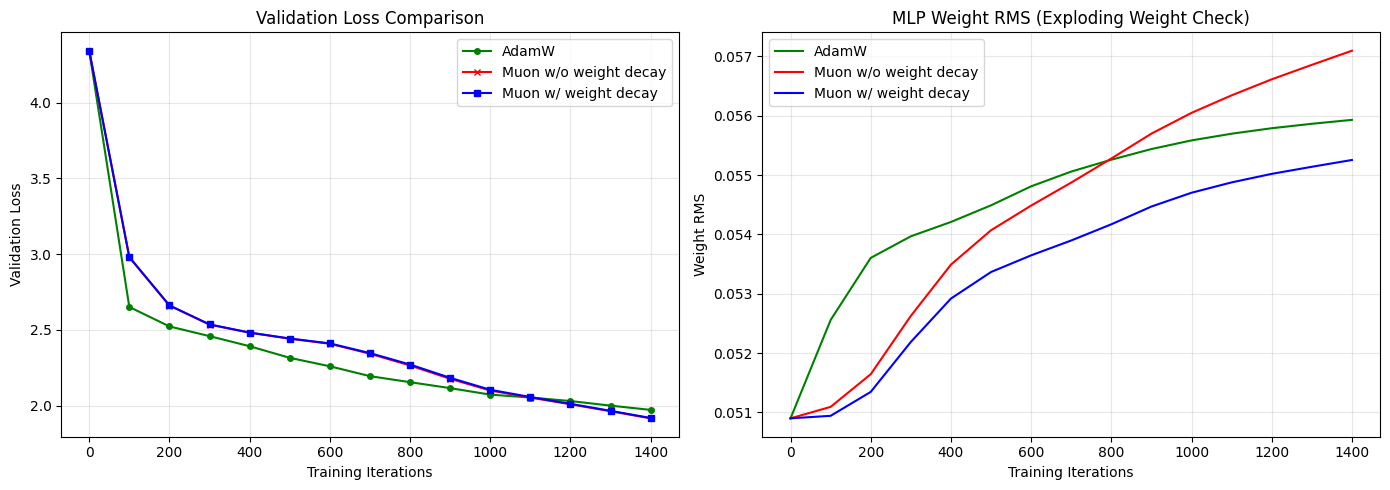

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Validation Loss (Recreating Figure 2)
ax1.plot(results_adamw['iter'], results_adamw['val_loss'], label='AdamW', color='green', marker='o', markersize=4)
ax1.plot(results_vanilla_muon['iter'], results_vanilla_muon['val_loss'], label='Muon w/o weight decay', color='red', marker='x', markersize=4)
ax1.plot(results_muon_wd['iter'], results_muon_wd['val_loss'], label='Muon w/ weight decay', color='blue', marker='s', markersize=4)
ax1.set_title("Validation Loss Comparison")
ax1.set_xlabel("Training Iterations")
ax1.set_ylabel("Validation Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: MLP Weight RMS to show exploding weights in Vanilla Muon
ax2.plot(results_adamw['iter'], results_adamw['mlp_rms'], label='AdamW', color='green')
ax2.plot(results_vanilla_muon['iter'], results_vanilla_muon['mlp_rms'], label='Muon w/o weight decay', color='red')
ax2.plot(results_muon_wd['iter'], results_muon_wd['mlp_rms'], label='Muon w/ weight decay', color='blue')
ax2.set_title("MLP Weight RMS (Exploding Weight Check)")
ax2.set_xlabel("Training Iterations")
ax2.set_ylabel("Weight RMS")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()